In [1]:
import json
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, ttest_ind

from plotting_tools import * 

In [2]:
plot_path = f"../plots/dx_sims"
os.makedirs(plot_path, exist_ok=True)

In [3]:
with open('../../2_simulation/hev_sim_results.json') as f:
    results = json.load(f)

In [4]:
stats_out = {}

for scenario, seeds in results.items():
    print(f"\n=== Scenario {scenario} ===")
    scenario_stats = {}

    for seed, out in seeds.items():

        lockdown = np.array(out["case_result_l"])
        nonlock = np.array(out["case_result_nl"])

        t_stat, t_p = ttest_ind(lockdown, nonlock, equal_var=False)
        u_stat, u_p = mannwhitneyu(lockdown, nonlock, alternative='two-sided')

        scenario_stats[seed] = {
            "t_stat": float(t_stat),
            "t_p_value": float(t_p),
            "t_significant_0.05": t_p < 0.05,
            "u_stat": float(u_stat),
            "u_p_value": float(u_p),
            "u_significant_0.05": u_p < 0.05,
            "mean_lockdown": float(np.mean(lockdown)),
            "mean_nonlock": float(np.mean(nonlock)),
        }

        print(
            f"Seed {seed}: p = {t_p:.3f} or {u_p:.3f} "
            f"(means: LD={np.mean(lockdown):.2f}, NL={np.mean(nonlock):.2f}) "
            f"→ significant = {t_p < 0.05} and {u_p < 0.05}"
        )

    stats_out[scenario] = scenario_stats


=== Scenario 0.000 ===
Seed 1: p = 0.025 or 0.004 (means: LD=1.04, NL=1.46) → significant = True and True
Seed 2: p = 0.958 or 0.912 (means: LD=1.16, NL=1.15) → significant = False and False
Seed 3: p = 0.708 or 0.850 (means: LD=1.27, NL=1.20) → significant = False and False
Seed 4: p = 0.976 or 0.989 (means: LD=1.39, NL=1.39) → significant = False and False
Seed 5: p = 0.661 or 0.736 (means: LD=1.24, NL=1.16) → significant = False and False
Seed 6: p = 0.189 or 0.100 (means: LD=1.15, NL=1.37) → significant = False and False
Seed 7: p = 0.510 or 0.970 (means: LD=1.34, NL=1.21) → significant = False and False
Seed 8: p = 0.221 or 0.575 (means: LD=1.37, NL=1.11) → significant = False and False
Seed 9: p = 0.154 or 0.016 (means: LD=1.04, NL=1.32) → significant = False and True
Seed 10: p = 0.904 or 0.953 (means: LD=1.10, NL=1.08) → significant = False and False
Seed 11: p = 0.436 or 0.444 (means: LD=1.22, NL=1.36) → significant = False and False
Seed 12: p = 0.689 or 0.683 (means: LD=1.0

In [5]:
rows = []
for scenario, seeds in stats_out.items():
    for seed, vals in seeds.items():
        rows.append({
            "scenario": float(scenario),          
            "seed": int(seed),
            "mean_ld": vals["mean_lockdown"],
            "mean_nl": vals["mean_nonlock"],
            "welch_sig": vals["t_p_value"] < 0.05,
            "mw_sig": vals["u_p_value"] < 0.05, 
        })

df = pd.DataFrame(rows)
df["diff"] = df["mean_nl"] - df["mean_ld"]

summary = (df.groupby("scenario").agg(
          mean_diff = ("diff", "mean"),
          diff_low  = ("diff", lambda x: np.percentile(x, 2.5)),
          diff_high = ("diff", lambda x: np.percentile(x, 97.5)),
          prop_sig_welch  = ("welch_sig", "mean"),
          prop_sig_mw  = ("mw_sig", "mean"))
      .reset_index()
      .sort_values("scenario")
)

print(summary)

    scenario  mean_diff  diff_low  diff_high  prop_sig_welch  prop_sig_mw
0        0.0   0.000167 -0.273232   0.344051            0.03         0.05
1        0.1   0.100699 -0.199065   0.435335            0.10         0.13
2        0.2   0.153408 -0.111932   0.437955            0.10         0.12
3        0.3   0.256508 -0.047651   0.584683            0.29         0.32
4        0.4   0.363826  0.053145   0.697625            0.49         0.49
5        0.5   0.458818  0.184313   0.784229            0.70         0.66
6        0.6   0.525485  0.242976   0.880860            0.81         0.81
7        0.7   0.559665  0.174199   0.878403            0.80         0.82
8        0.8   0.703799  0.385745   1.008325            0.95         0.95
9        0.9   0.740871  0.467582   1.049046            0.99         0.98
10       1.0   0.785956  0.455629   1.191523            1.00         0.99


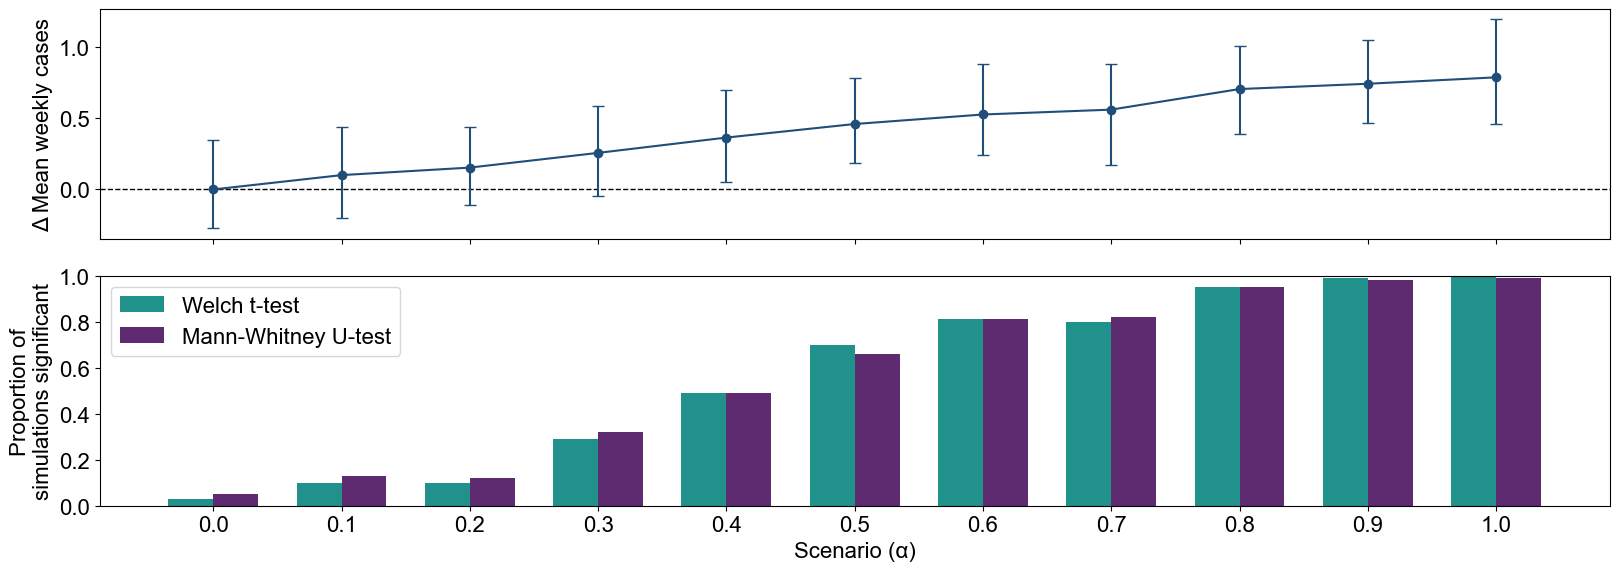

In [12]:
plt.style.use('default')
set_fontsize()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16.6, 6), sharex=True)
x = np.arange(len(summary))
width = 0.35
scenarios = summary["scenario"]

ax1.errorbar(x, summary["mean_diff"], 
             yerr=[summary["mean_diff"] - summary["diff_low"], summary["diff_high"] - summary["mean_diff"]],
             fmt="o-", capsize=4, color = darkblue)
ax1.axhline(0, color='black', linestyle='--', linewidth=1, zorder = -10)
ax1.set_ylabel("Δ Mean weekly cases")

ax2.bar(x - width/2, summary["prop_sig_welch"], width, label="Welch t-test", color = teal)
ax2.bar(x + width/2, summary["prop_sig_mw"], width, label="Mann-Whitney U-test", color = purple)
ax2.set_xticks(x)
ax2.set_xticklabels(summary["scenario"])
ax2.set_xlabel("Scenario (α)")
ax2.set_ylabel("Proportion of\nsimulations significant")
ax2.set_ylim(0, 1)
ax2.legend()

plt.tight_layout()
plt.savefig(f"{plot_path}/dx_sig_summary.png", dpi=300)
plt.show()

In [7]:
rows = []
for scenario, seeds in results.items():
    for seed, out in seeds.items():
        for c in out["case_result_l"]:
            rows.append({"scenario": scenario, "particle": seed, "Category": "Lockdown", "cases": c})
        for c in out["case_result_nl"]:
            rows.append({"scenario": scenario, "particle": seed, "Category": "Non-Lockdown","cases": c})

sim_cases = pd.DataFrame(rows)
sim_cases['scenario'] = sim_cases['scenario'].astype(float)

In [8]:
sim_cases.head()

,scenario,particle,Category,cases
0,0.0,1,Lockdown,3
1,0.0,1,Lockdown,2
2,0.0,1,Lockdown,0
3,0.0,1,Lockdown,2
4,0.0,1,Lockdown,2


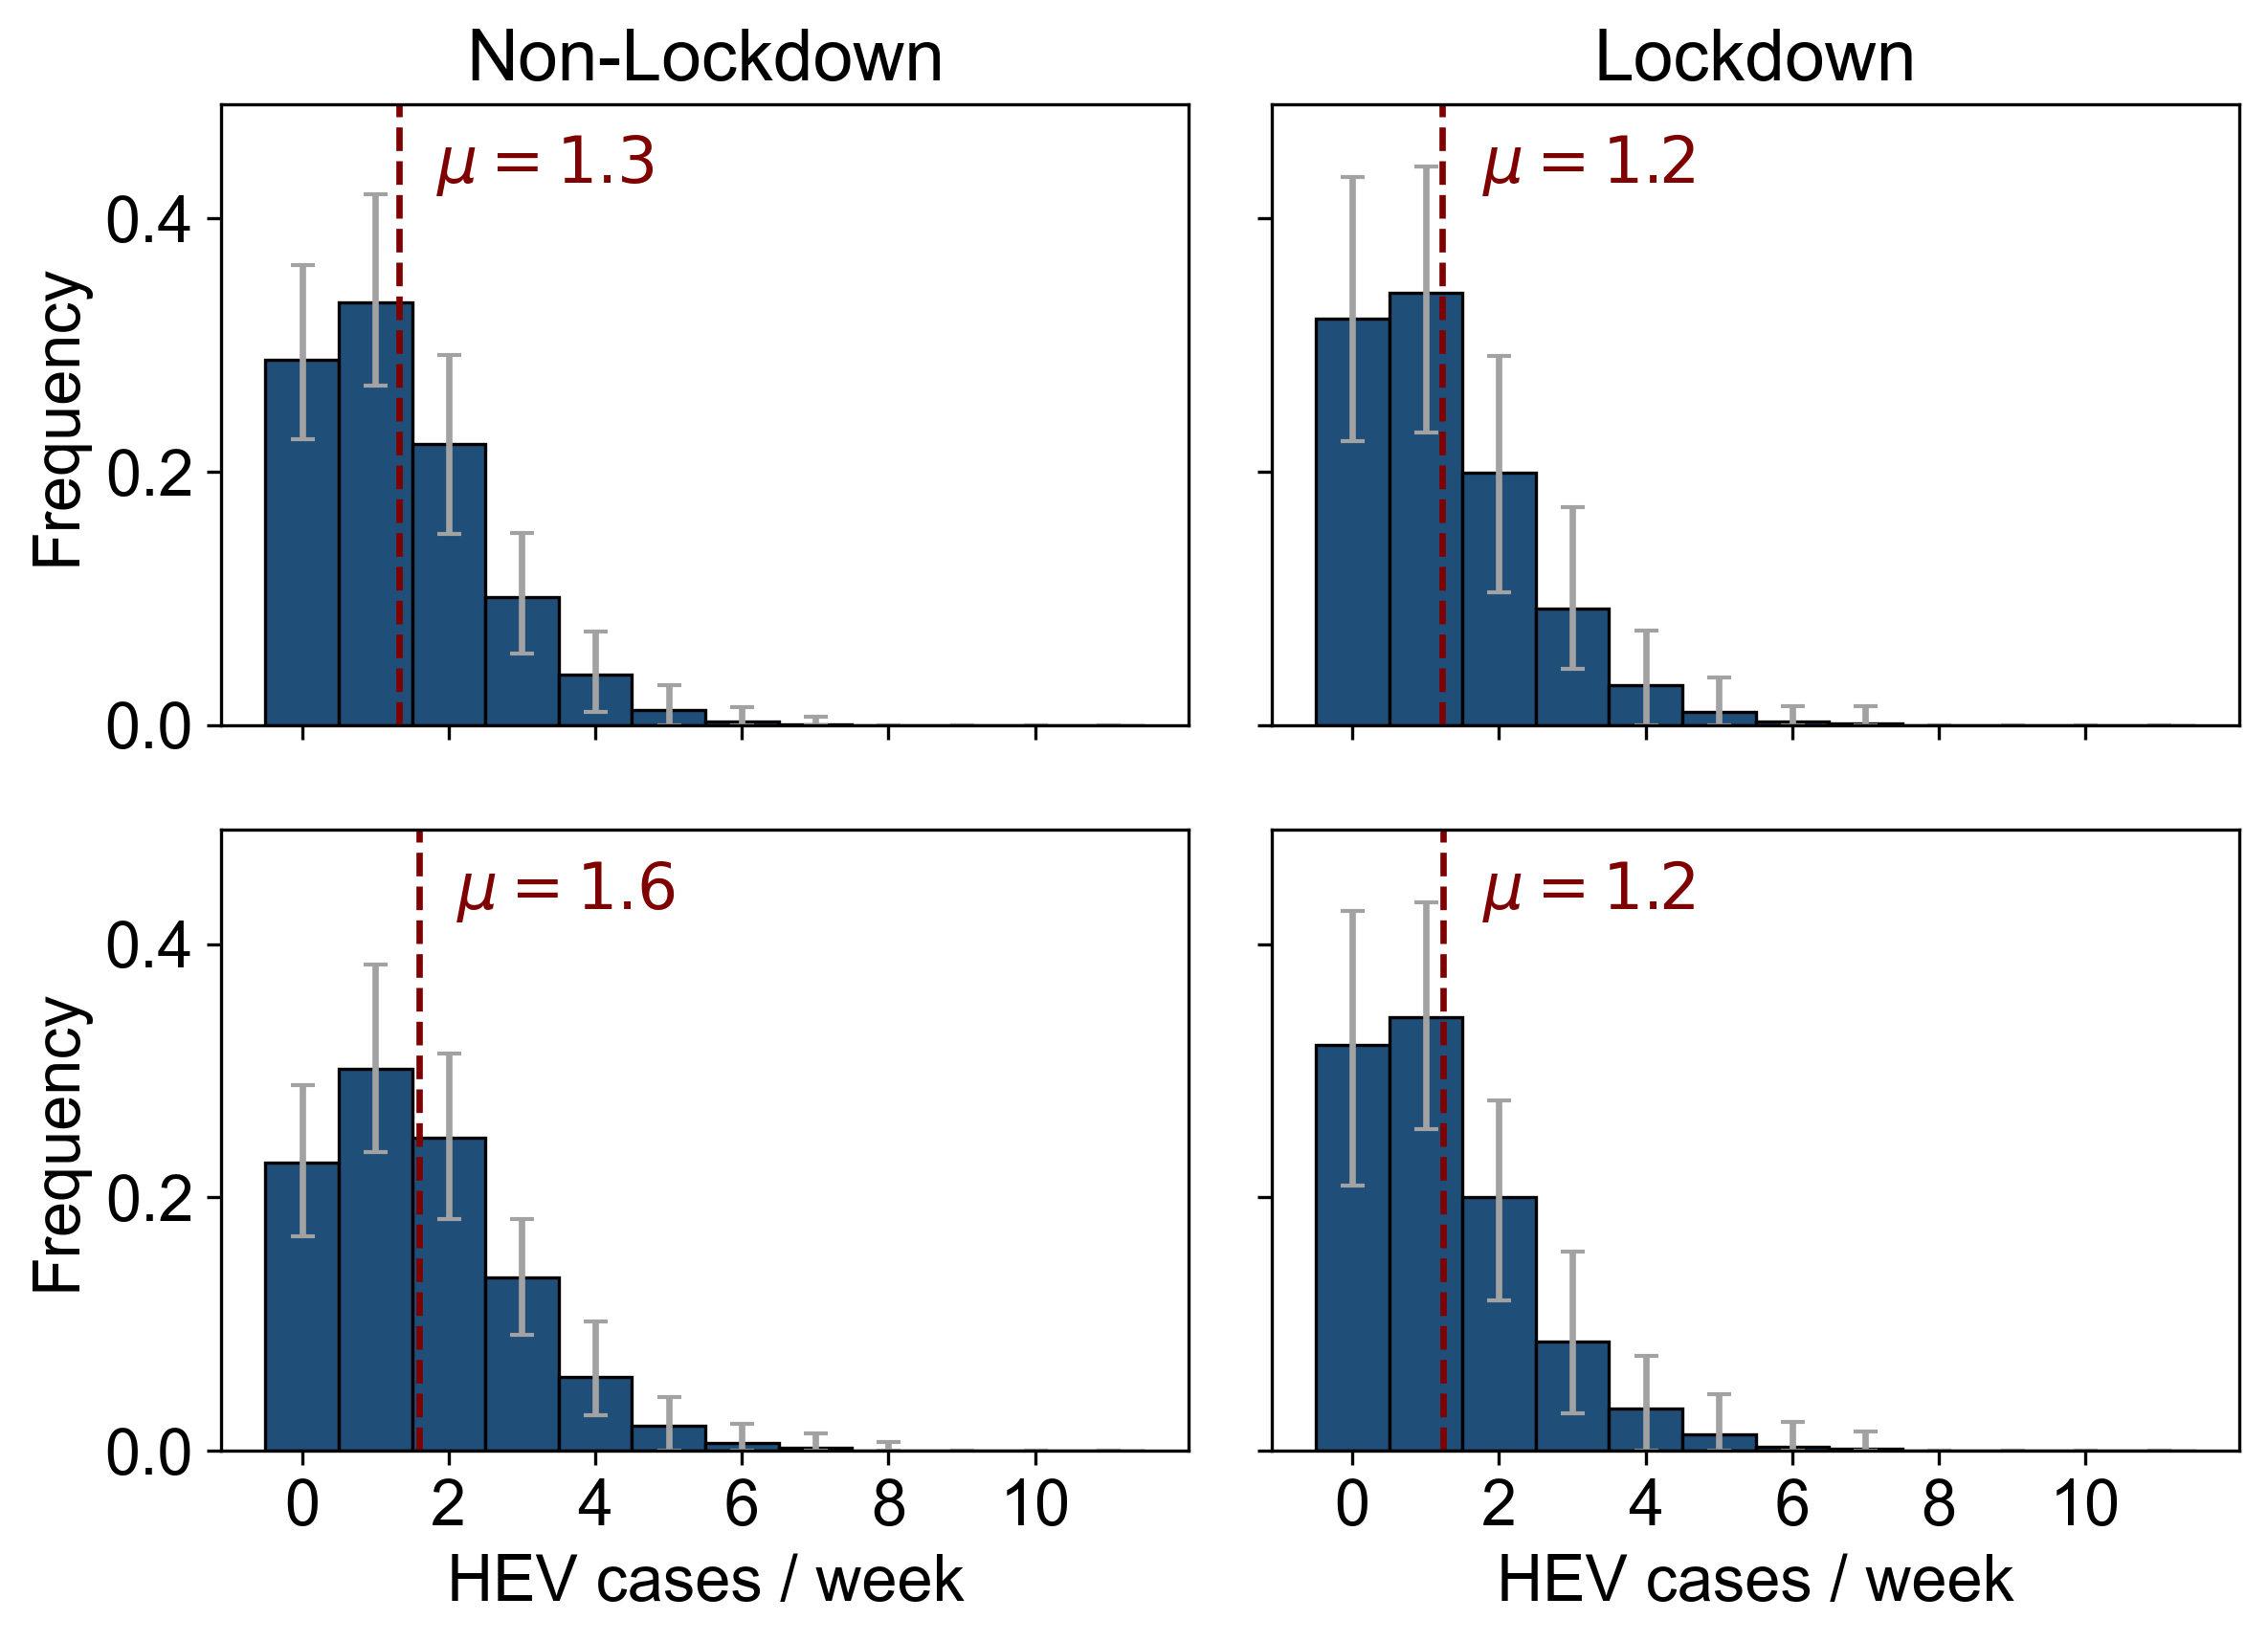

In [9]:
plt.style.use('default')
set_fontsize()

selected_scenarios = [0.1, 0.4]
sim_sub = sim_cases[sim_cases['scenario'].isin(selected_scenarios)]

min_count = sim_sub['cases'].min()
max_count = 11 # sim_sub['cases'].max()
counts = np.arange(min_count, max_count + 1)

nrows = len(selected_scenarios)
ncols = 2

fig, axes = plt.subplots(figsize=(8.18, 3 * nrows), nrows=nrows, ncols=ncols, dpi=300, sharex=True, sharey=True)

for row_idx, scen in enumerate(selected_scenarios):
    row_axes = axes[row_idx]
    row_axes[0].set_ylabel(f"Frequency")
    #row_axes[0].set_ylabel(f"Frequency\nα = {scen}")

    for ax, cat in zip(row_axes, ['Non-Lockdown', 'Lockdown']):
        barw = 1
        ssub = sim_sub[(sim_sub['scenario'] == scen) & (sim_sub['Category'] == cat)]

        sim_mat = (ssub.groupby(['particle', 'cases']).size().unstack(fill_value=0)
                   .reindex(columns=counts, fill_value=0).to_numpy())
        sim_mat = sim_mat / sim_mat.sum(axis=1, keepdims=True)

        sim_mean = sim_mat.mean(axis=0)
        sim_lo = np.percentile(sim_mat, 2.5, axis=0)
        sim_hi = np.percentile(sim_mat, 97.5, axis=0)
        lower_err = np.maximum(0, sim_mean - sim_lo)
        upper_err = np.maximum(0, sim_hi - sim_mean)
        yerr = np.vstack([lower_err, upper_err])

        ax.bar(counts, sim_mean, width=barw, facecolor=darkblue, edgecolor="black", linewidth=0.8, label="Mean across sims")
        ax.errorbar(counts, sim_mean, yerr=yerr, fmt='none', ecolor=medium_grey, elinewidth=1.6, capsize=3, label="95% interval")
        ax.set_ylim(0, 0.49)
        
        mean_cases = ssub.groupby("particle")["cases"].mean().mean()
        ax.axvline(mean_cases, color=maroon, linestyle="--", linewidth=1.6)
        mean_text = rf"$\mu = {mean_cases:.1f}$"
        ax.annotate(mean_text, xy=(mean_cases + 2, 0.4), xytext=(0, 5), textcoords="offset points", 
                    ha="center", va="bottom", fontsize=16, color=maroon)
        
        if row_idx == 0:
            ax.set_title(cat)
        else:
            ax.set_title("")
            
        if row_idx == (nrows - 1):
            ax.set_xlabel("HEV cases / week")
        else:
            ax.set_xlabel("")
        
        ax.set_xticks([0, 2, 4, 6, 8, 10])

# handles, labels = axes[0, 0].get_legend_handles_labels()
# fig.legend(handles, labels, loc="upper right", frameon=False)

plt.tight_layout()
plt.savefig(f"{plot_path}/hist_by_alpha_1.png", dpi=300)
plt.show()

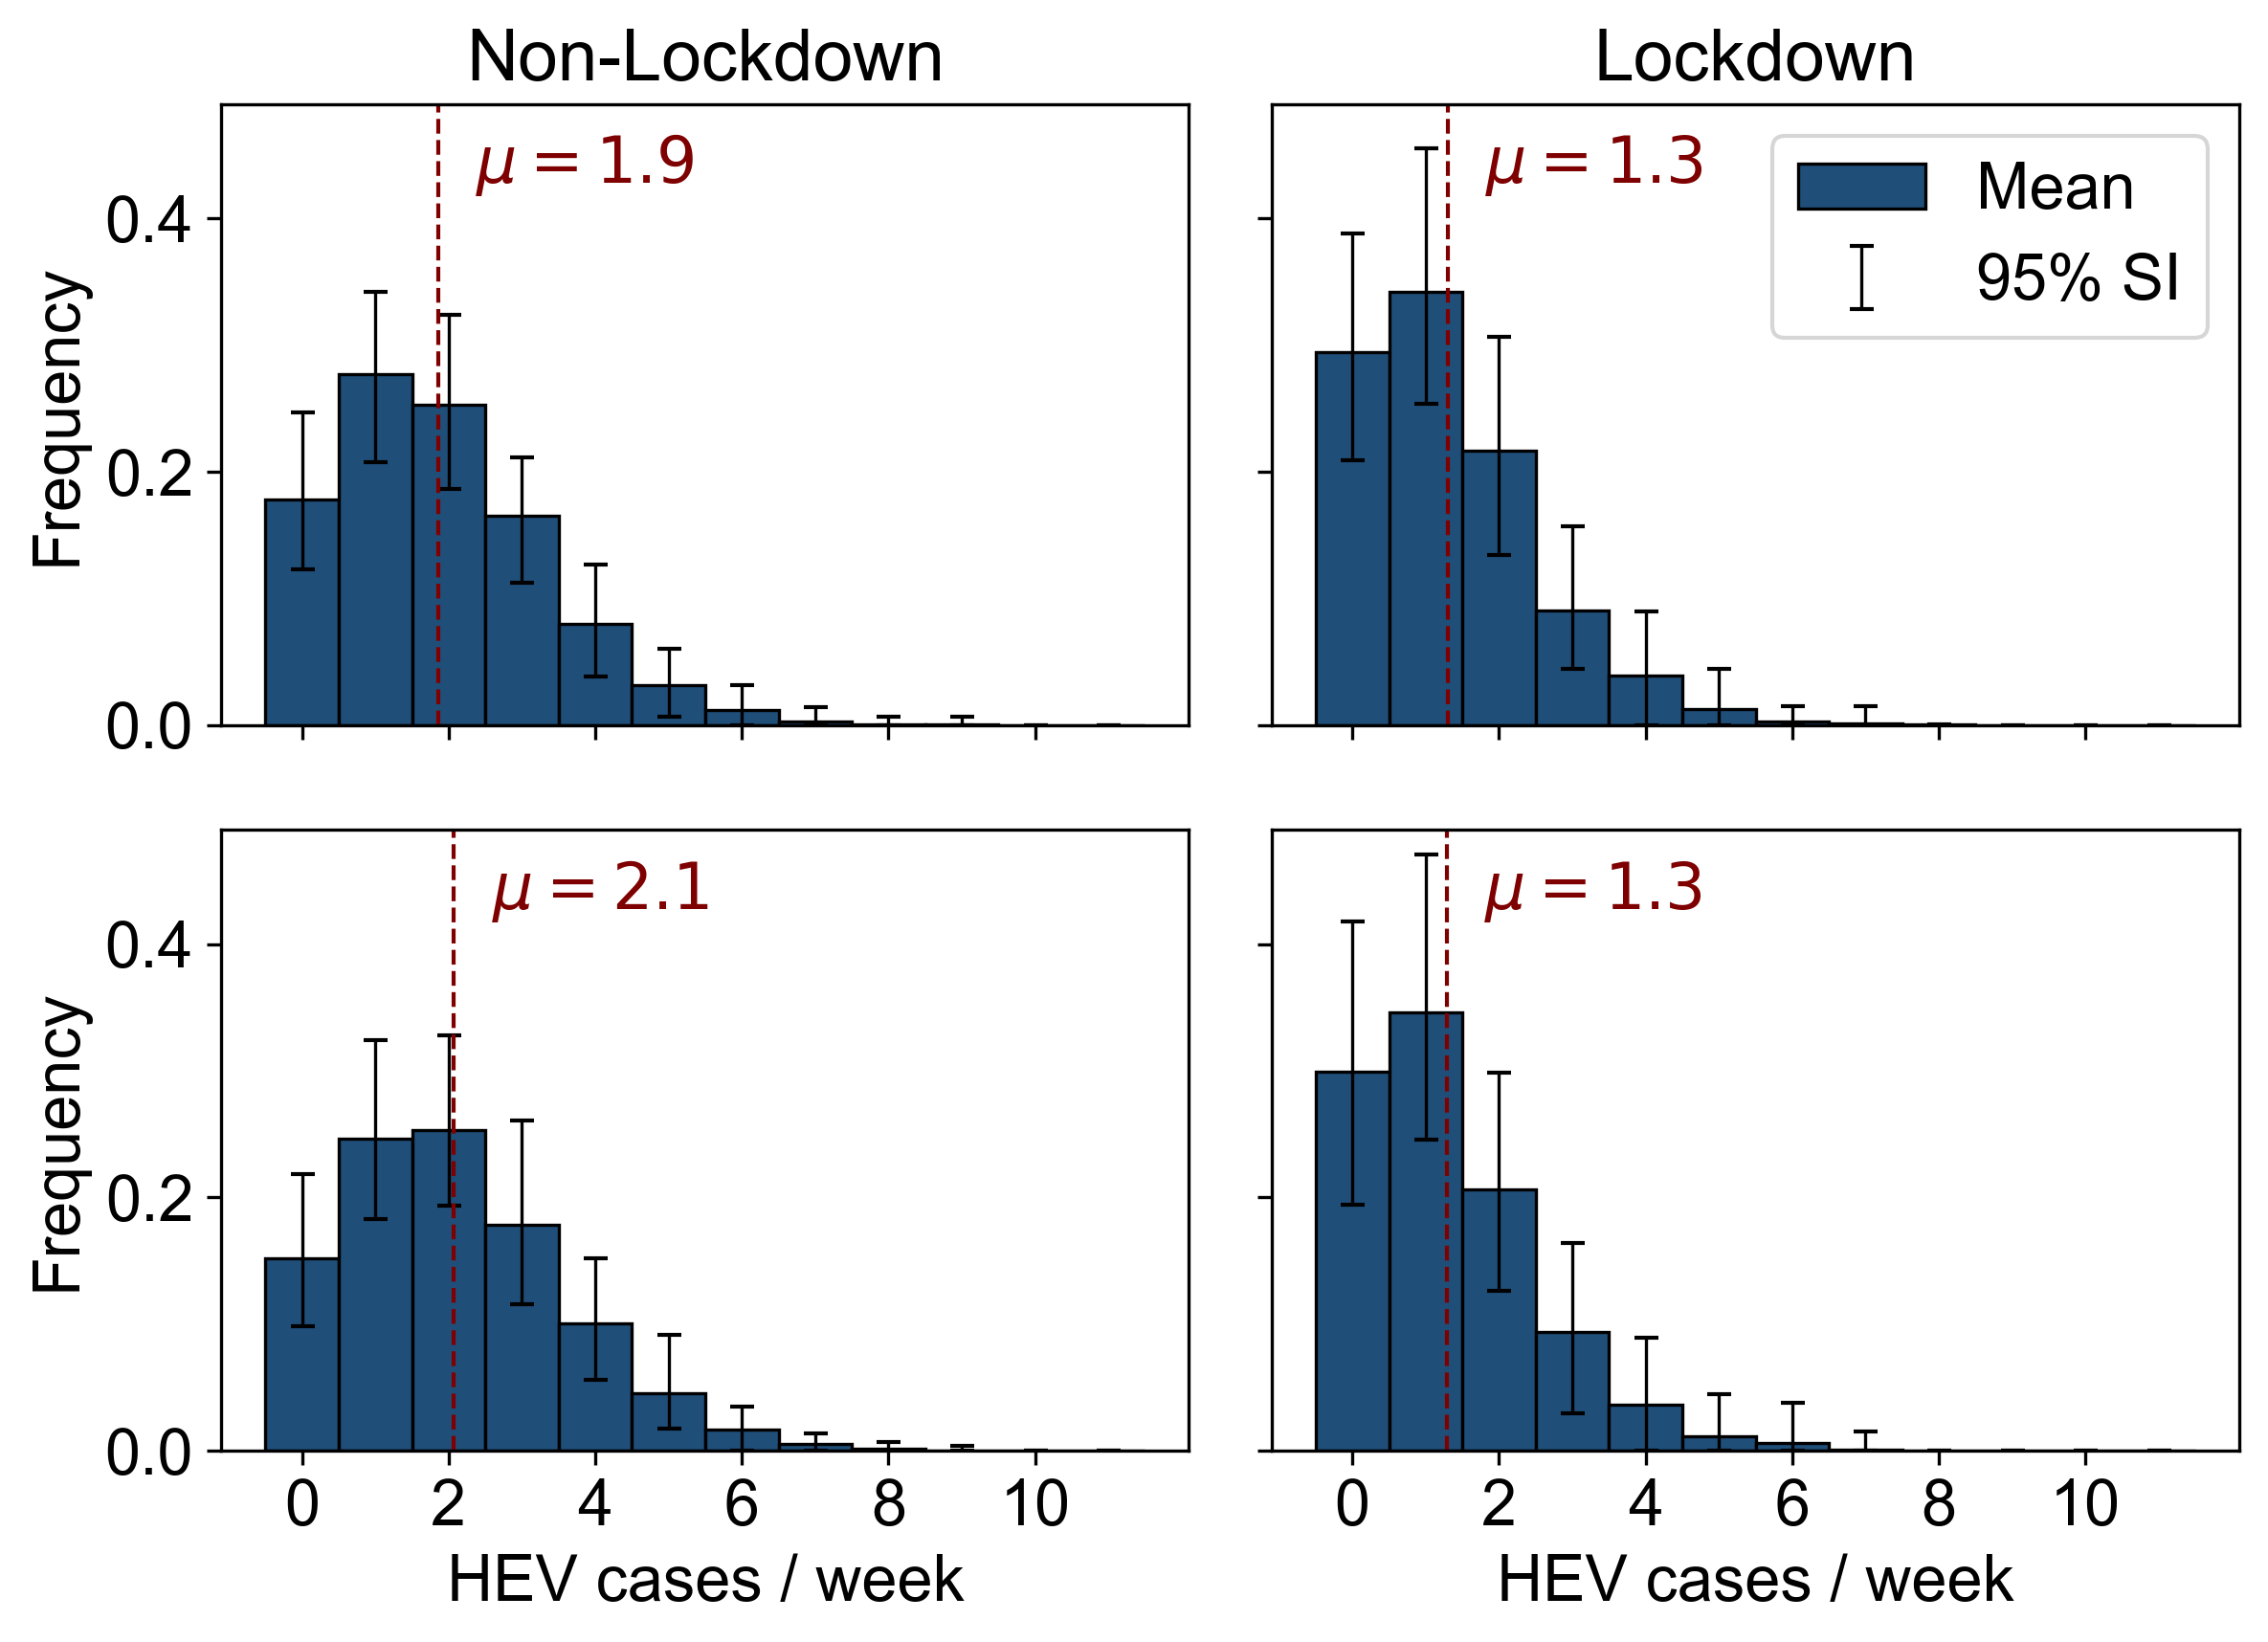

In [24]:
plt.style.use('default')
set_fontsize()

selected_scenarios = [0.7, 1]
sim_sub = sim_cases[sim_cases['scenario'].isin(selected_scenarios)]

min_count = sim_sub['cases'].min()
max_count = sim_sub['cases'].max()
counts = np.arange(min_count, max_count + 1)

nrows = len(selected_scenarios)
ncols = 2

fig, axes = plt.subplots(figsize=(8.18, 3 * nrows), nrows=nrows, ncols=ncols, dpi=300, sharex=True, sharey=True)

for row_idx, scen in enumerate(selected_scenarios):
    row_axes = axes[row_idx]
    row_axes[0].set_ylabel(f"Frequency")
    #row_axes[0].set_ylabel(f"Frequency\nα = {scen}")

    for ax, cat in zip(row_axes, ['Non-Lockdown', 'Lockdown']):
        barw = 1
        ssub = sim_sub[(sim_sub['scenario'] == scen) & (sim_sub['Category'] == cat)]

        sim_mat = (ssub.groupby(['particle', 'cases']).size().unstack(fill_value=0)
                   .reindex(columns=counts, fill_value=0).to_numpy())
        sim_mat = sim_mat / sim_mat.sum(axis=1, keepdims=True)

        sim_mean = sim_mat.mean(axis=0)
        sim_lo = np.percentile(sim_mat, 2.5, axis=0)
        sim_hi = np.percentile(sim_mat, 97.5, axis=0)
        lower_err = np.maximum(0, sim_mean - sim_lo)
        upper_err = np.maximum(0, sim_hi - sim_mean)
        yerr = np.vstack([lower_err, upper_err])

        ax.bar(counts, sim_mean, width=barw, facecolor=darkblue, edgecolor="black", linewidth=0.8, label="Mean")
        ax.errorbar(counts, sim_mean, yerr=yerr, fmt='none', ecolor=medium_grey, elinewidth=1.6, capsize=3, label="95% SI")
        ax.set_ylim(0, 0.49)
        
        mean_cases = ssub.groupby("particle")["cases"].mean().mean()
        ax.axvline(mean_cases, color=maroon, linestyle="--", linewidth=1.6)
        mean_text = rf"$\mu = {mean_cases:.1f}$"
        ax.annotate(mean_text, xy=(mean_cases + 2, 0.4), xytext=(0, 5), textcoords="offset points", 
                    ha="center", va="bottom", fontsize=16, color=maroon)
        
        if row_idx == 0:
            ax.set_title(cat)
        else:
            ax.set_title("")
            
        if row_idx == (nrows - 1):
            ax.set_xlabel("HEV cases / week")
        else:
            ax.set_xlabel("")
            
        if row_idx == 0 and cat == 'Lockdown':
            ax.legend(loc='upper right', frameon=True)
        
        ax.set_xticks([0, 2, 4, 6, 8, 10])

plt.tight_layout()
plt.savefig(f"{plot_path}/hist_by_alpha_2.png", dpi=300)
plt.show()